# TCBench: Quick Start

**Goal.** This notebook walks through a minimal, end-to-end workflow to evaluate tropical-cyclone (TC) **track** and **intensity** forecasts on the **2023** test year with the TCBench toolbox and local CSV files.
It loads IBTrACS, (optionally) matches raw model tracks to IBTrACS storms, evaluates every model track file against the IBTrACS ground truth, and builds the summary tables, scorecards and figures used in the paper.

**Pipeline at a glance:**

| Step | Script | Configured by | Writes |
|---|---|---|---|
| Match raw tracks to IBTrACS (optional) | `track_matcher.py` | command-line flags | `<model>.csv` |
| Evaluate | `evaluate_tracks.py` | `evaluate_tracks_config.yaml` | `<model>_det_<tag>.csv`, `<model>_prob_<tag>.csv`, `<model>_ri_<tag>.csv`, IBTrACS ground truth, baselines |
| Summarize and plot | `plot_errors.py` | `plot_errors_config.yaml` | `summary_*.csv`, `coverage_*.csv`, `detail_*.csv`, figures (PDF), RI contingency table (LaTeX) |

`<tag>` is `<year>` (all basins) or `<year>_<basin>`.

Both `evaluate_tracks.py` and `plot_errors.py` take their run settings from a YAML file next to the script, instead of command-line arguments. This notebook reads the evaluation config, lets you override it in a cell, and calls the evaluation function directly. The plotting script reads its config when it runs, so its settings are changed by editing `plot_errors_config.yaml`.

> This notebook is **self-contained and runs offline**.

In [1]:
import os
import sys
import subprocess
from pathlib import Path

import yaml
import pandas as pd

# The kernel is expected to be launched from the dev folder, which holds the
# TCBench scripts and their YAML configs. Relative paths in the configs (and in
# this notebook) are resolved from it.
DEV_DIR = Path.cwd()
EVAL_CONFIG = DEV_DIR / "evaluate_tracks_config.yaml"
PLOT_CONFIG = DEV_DIR / "plot_errors_config.yaml"
if not EVAL_CONFIG.exists():
    raise FileNotFoundError(
        f"{EVAL_CONFIG} not found: launch the kernel from the dev folder (or os.chdir to it)."
    )
if str(DEV_DIR) not in sys.path:
    sys.path.insert(0, str(DEV_DIR))

with open(EVAL_CONFIG) as f:
    eval_cfg = yaml.safe_load(f)

eval_cfg

{'eval_directory': 'results',
 'ibtracs_tracks_path': 'data/ibtracs',
 'year': 2023,
 'basin': None,
 'lead_hours': None,
 'select_files': None,
 'recompute': True,
 'verbose': True,
 'ensemble_fraction': 0.3,
 'ri_thresh': 30,
 'ri_window': 24,
 'ri_ens_fraction': 0.3}

#### Evaluation settings (`evaluate_tracks_config.yaml`)

| Key | Meaning |
|---|---|
| `eval_directory` | Folder with the model track files (`*.csv`). The ground truth, baselines and results are written here too. |
| `ibtracs_tracks_path` | The IBTrACS CSV (`ibtracs.ALL.list.v04r01.csv`), **or** a folder holding it as its only file. |
| `year` | Forecasts initialized in this year are evaluated. |
| `basin` | `NA`, `EP`, `WP`, `NI`, `SI`, `SP`, or `null` for all basins. See the note on basins in the plotting section. |
| `lead_hours` | `null` (all leads), a list such as `[6, 12, 24, 48]`, or a `start` / `stop` / `step` range. |
| `select_files` | File names inside `eval_directory` to evaluate, or `null` to evaluate every track file found there. |
| `recompute` | Rebuild the IBTrACS ground truth and baselines even if they already exist. Model results are always rewritten. |
| `ensemble_fraction` | Minimum fraction of valid ensemble members for a case to be scored. |
| `ri_thresh`, `ri_window` | Rapid intensification: a wind increase of `ri_thresh` kt over `ri_window` h. |
| `ri_ens_fraction` | For ensembles, the fraction of members showing RI needed to flag a case as RI. |

#### `Schema for Probabilistic Models`

| sid | initial_time | valid_time | ensemble_idx | wind_max | pressure_min | lat | lon |
|-----|-------------|------------|:------------:|:--------:|:------------:|:---:|:---:|
| 2023005S18142 | 2023-01-06 18:00:00 | 2023-01-06 18:00:00 | 0 | 51.2 | 995.2 | -20.0 | 152.75 |

---

#### `Schema for Deterministic Models`

| sid | initial_time | valid_time | wind_max | pressure_min | lat | lon |
|-----|-------------|------------|:--------:|:------------:|:---:|:---:|
| 2023005S18142 | 2023-01-09 12:00:00 | 2023-01-10 12:00:00 | 29.58 | 985.65 | -36.75 | 176.5 |

- `sid`, `initial_time` and `valid_time` are **required**. A file is scored on whichever of `wind_max` (kt), `pressure_min` (hPa) and `lat`/`lon` (degrees) it contains, so intensity-only or track-only models work too.
- A file with an `ensemble_idx` column is treated as an ensemble (members `0 … N-1`) and also gets the probabilistic metrics.
- Column names are lower case with underscores. The older names (`SID`, `Initial Time`, `wind max`, …) are **no longer recognized**.
- Files can include additional columns that are ignored during processing (e.g., cyclone names, basins).

## Load the IBTrACS test set (ground truth)
**IBTrACS** (International Best Track Archive for Climate Stewardship) is the
global reference archive of tropical cyclone “best tracks,” compiled from all
basin warning centers and harmonized by NOAA. It provides a consistent,
time-ordered record of each storm’s location and intensity through its life
cycle. We use IBTrACS as the **ground truth** for verifying model tracks and
intensities.

`ibtracs_tracks_path` can point either to the CSV itself (`ibtracs.ALL.list.v04r01.csv`) or to a folder that holds it as its only file. The file contains the
global record. The evaluation subsets it to the evaluation year and verifies on the
standard **6-hour grid** (00/06/12/18 UTC), with intensities referenced to the
“USA” source used in IBTrACS.

---

### Columns used in IBTrACS

| Column        | Type / Units                 | Description                                                                                             | Notes |
|---            |---                           |---                                                                                                      |---|
| `SID`         | string                       | Unique storm identifier within IBTrACS.                                                                 | Becomes `sid` in the ground truth. |
| `SEASON`      | integer (year)               | Season year of the storm.                                                                               |  |
| `BASIN`       | categorical                  | Basin code (e.g., `NA` North Atlantic, `WP` West Pacific, `EP` East Pacific, `NI` North Indian, `SI` South Indian, `SP` South Pacific). | Used for the basin evaluation. |
| `SUBBASIN`    | categorical / string         | Sub-basin code where available.                                                                         | |
| `NAME`        | string                       | Storm name (if assigned).                                                                               |  |
| `ISO_TIME`    | datetime (UTC, ISO-8601)     | Analysis time for this record.                                                                          | Nominally 6-hourly; only 00/06/12/18 UTC records are used. |
| `NATURE`      | categorical                  | Storm nature/class (e.g., `TS`, `ET`, `DS`).                                                            | |
| `LAT`         | float (degrees)              | Storm center latitude.                                                                                  | Becomes `lat`. |
| `LON`         | float (degrees)              | Storm center longitude.                                                                                 | Becomes `lon`. |
| `USA_ATCF_ID` | string                       | ATCF storm identifier from the USA source (e.g., `AL012023`, `WP192023`).                               |  |
| `USA_WIND`    | float (knots)                | **Maximum 1-minute sustained wind** from the USA source at `ISO_TIME`.                                  | Ground-truth `wind_max`. |
| `USA_PRES`    | float (hPa)                  | **Minimum central pressure** from the USA source at `ISO_TIME`.                                         | Ground-truth `pressure_min`. |

In [2]:
from utils import toolbox

# A folder holding the IBTrACS CSV as its only file, or the CSV itself
ibtracs = toolbox.read_hist_track_file(tracks_path=eval_cfg["ibtracs_tracks_path"])

ibtracs = ibtracs[ibtracs["ISO_TIME"].dt.year == eval_cfg["year"]]
ibtracs.sample(5)

/opt/venv/lib/python3.11/site-packages/numcodecs/__init__.py:106: DeprecationWarning: crc32c usage is deprecated since numcodecs v0.16.4. It is recommended to install google_crc32c instead.
  from numcodecs.checksum32 import CRC32, Adler32, JenkinsLookup3
/opt/venv/lib/python3.11/site-packages/pandas/io/formats/format.py:1458: RuntimeWarning: overflow encountered in cast
  has_large_values = (abs_vals > 1e6).any()


,SID,SEASON,BASIN,SUBBASIN,NAME,ISO_TIME,NATURE,LAT,LON,USA_ATCF_ID,USA_WIND,USA_PRES
710684,2023273N16073,2023,NI,AS,UNNAMED,2023-09-30 21:00:00,TS,16.90625,73.6875,,,
710941,2023289N15111,2023,WP,MM,SANBA,2023-10-20 03:00:00,TS,21.00000,109.6875,WP162023,38,1003
706566,2023054S19117,2023,SI,WA,UNNAMED,2023-03-01 21:00:00,NR,-17.00000,131.1250,,,
709621,2023241N10158,2023,WP,MM,KIROGI,2023-08-31 12:00:00,TS,17.90625,153.6250,WP112023,55,992
711565,2023326N10240,2023,EP,MM,RAMON,2023-11-25 09:00:00,TS,14.50000,237.0000,EP202023,35,1004


### Matching tracks using HuracánPy (optional)

Skip this step if your model's tracks are already in the schema above.

This cell runs the track matching script. It assumes there is a folder named after your model, holding one file per forecast initial time. Concretely, it:

1) **Loads the tracks** detected in the model outputs, as well as the IBTrACS tracks.
2) **Matches the detected tracks** to known storms using HuracánPy.
3) **Builds a dataframe** holding, for each matched storm, the detected track's time series of wind speed, pressure, lat and lon.
4) **Writes the CSV** in the deterministic schema above, converting the wind speed from m/s to knots and the pressure from Pa to hPa (assuming the tracks use the default ERA5 units).

Script arguments:

**--model** The script looks for a directory named `<model>` inside the `data` subdirectory of its working directory (`DEV_DIR` below). This directory should contain individual files named:
>> \<model-tag\>\_YYYY.MM.DD-HHhMMm\_\<any-other-tags\>.csv
where HH and MM are the hour and minute digits.

**--ibtracs_path** The IBTrACS CSV to match against. This script needs the **file** itself, not its folder.

**--output_path** Where to write the matched tracks. The default is `<working_dir>/outputs/<model>.csv`. Here we write directly into `eval_directory`, so the file is ready for evaluation.

In [3]:
RUN_MATCHING = False  # set to True to match a model's raw tracks

MODEL = "2023_pangu"  # folder data/<MODEL> inside the dev folder
IBTRACS_CSV = "data/ibtracs/ibtracs.ALL.list.v04r01.csv"
matched_csv = Path(eval_cfg["eval_directory"]) / f"{MODEL}.csv"

if RUN_MATCHING:
    match_command = [
        sys.executable,
        "track_matcher.py",
        "--model", MODEL,
        "--ibtracs_path", IBTRACS_CSV,
        "--output_path", str(matched_csv),
    ]
    subprocess.check_call(match_command, cwd=DEV_DIR)

    print(f"Matched tracks written to {matched_csv}")
    display(pd.read_csv(matched_csv).head())

### Evaluate the track files

This cell runs `evaluate_tracks` over the model track files in `eval_directory` and verifies them against IBTrACS. Concretely, it:

1) **Builds the ground truth** `ibtracs_gt_<tag>.csv`: every 00/12Z IBTrACS initialization of the year, paired with its 6-hourly valid times. It also builds two intensity baselines next to it, `<year>_CLIM-intensity.csv` (mean tendency climatology) and `<year>_PERSISTENCE.csv` (persistence), named like the model files. These are rebuilt only when `recompute` is true or the ground truth file is missing.
2) **Discovers** the track files, or uses `select_files`. A CSV counts as a track file if it has the `sid`, `initial_time` and `valid_time` columns and its name does **not** contain `_2020` … `_2024`. That is how the results files are skipped, so don't put `_<year>` in a model file name. A leading year, as in `2023_PANGU.csv`, is the naming convention.
3) **Matches** each file to the ground-truth cases on `(sid, initial_time, valid_time)`, plus `ensemble_idx` for ensembles. Only forecasts initialized in `year` are kept.
4) **Computes the metrics** and writes, for each model:
   - `<model>_det_<tag>.csv`, the deterministic metrics: `AbsErr_*` and `SquErr_*` for `wind_max` / `pressure_min`, `DirPosErr` (great-circle distance, km), and `AlongTrack` / `CrossTrack` (signed, km). Ensembles are scored member by member.
   - `<model>_prob_<tag>.csv` (ensembles only), the probabilistic metrics: `FairCRPS_wind_max`, `FairCRPS_pressure_min`, `TrackCRPS`, and the probability circles `ProbCircle_r<p>` / `ProbCircle_hit<p>` for p = 10 … 90 %.
   - `<model>_ri_<tag>.csv` (models with `wind_max`): the 24-h intensification and the RI flag (`RI`) or, for ensembles, the RI member fraction (`RI_fraction`).

The function writes files and returns nothing. You can also run the whole step as a script, `python evaluate_tracks.py`, which uses the YAML settings unchanged.

In [4]:
from evaluate_tracks import evaluate_tracks

# Settings from evaluate_tracks_config.yaml; override any of them here
settings = dict(eval_cfg)
# settings["select_files"] = ["2023_PANGU.csv", "2023_GENCAST.csv"]
# settings["recompute"] = False  # reuse the ground truth and baselines already in eval_directory

# lead_hours: null (all), a list, or a start/stop/step range
leads = settings.get("lead_hours")
if isinstance(leads, dict):
    leads = list(range(leads["start"], leads["stop"] + 1, leads["step"]))

evaluate_tracks(
    settings["eval_directory"],
    settings["ibtracs_tracks_path"],
    lead_hours=leads,
    year=settings["year"],
    select_files=settings.get("select_files"),
    recompute=settings.get("recompute", False),
    basin=settings.get("basin") or None,
    verbose=settings.get("verbose", True),
    ensemble_fraction=settings.get("ensemble_fraction", 0.3),
    ri_thresh=settings.get("ri_thresh", 30),
    ri_window=settings.get("ri_window", 24),
    ri_ens_fraction=settings.get("ri_ens_fraction", 0.3),
)

[INFO] Evaluating track file: results/2023_AIFS.csv against IBTrACS ground truth.
[INFO] Deduplicated 65 rows for model '2023_AIFS' based on keys: ['sid', 'initial_time', 'valid_time']
[INFO] Saved deterministic metrics to results/2023_AIFS_det_2023.csv
[INFO] Saved RI results to results/2023_AIFS_ri_2023.csv
[INFO] Evaluating track file: results/2023_CLIM-intensity.csv against IBTrACS ground truth.
[INFO] Saved deterministic metrics to results/2023_CLIM-intensity_det_2023.csv
[INFO] Saved RI results to results/2023_CLIM-intensity_ri_2023.csv
[INFO] Evaluating track file: results/2023_FCNET.csv against IBTrACS ground truth.
[INFO] Deduplicated 68 rows for model '2023_FCNET' based on keys: ['sid', 'initial_time', 'valid_time']
[INFO] Saved deterministic metrics to results/2023_FCNET_det_2023.csv
[INFO] Saved RI results to results/2023_FCNET_ri_2023.csv
[INFO] Evaluating track file: results/2023_FNV3P2.csv against IBTrACS ground truth.


/home/mgomezd1/repos/iop_tcbench/dev/metrics.py:532: RuntimeWarning: Mean of empty slice
  abs_err = np.nanmean(


[INFO] Saved deterministic metrics to results/2023_FNV3P2_det_2023.csv
[INFO] Saved probabilistic metrics to results/2023_FNV3P2_prob_2023.csv
[INFO] Saved RI results to results/2023_FNV3P2_ri_2023.csv
[INFO] Evaluating track file: results/2023_GENCAST.csv against IBTrACS ground truth.
[INFO] Deduplicated 98938 rows for model '2023_GENCAST' based on keys: ['sid', 'initial_time', 'valid_time', 'ensemble_idx']


/home/mgomezd1/repos/iop_tcbench/dev/metrics.py:532: RuntimeWarning: Mean of empty slice
  abs_err = np.nanmean(


[INFO] Saved deterministic metrics to results/2023_GENCAST_det_2023.csv
[INFO] Saved probabilistic metrics to results/2023_GENCAST_prob_2023.csv
[INFO] Saved RI results to results/2023_GENCAST_ri_2023.csv
[INFO] Evaluating track file: results/2023_HMON.csv against IBTrACS ground truth.
[INFO] Deduplicated 11378 rows for model '2023_HMON' based on keys: ['sid', 'initial_time', 'valid_time']
[INFO] Saved deterministic metrics to results/2023_HMON_det_2023.csv
[INFO] Saved RI results to results/2023_HMON_ri_2023.csv
[INFO] Evaluating track file: results/2023_HWFI.csv against IBTrACS ground truth.
[INFO] Deduplicated 7400 rows for model '2023_HWFI' based on keys: ['sid', 'initial_time', 'valid_time']
[INFO] Saved deterministic metrics to results/2023_HWFI_det_2023.csv
[INFO] Saved RI results to results/2023_HWFI_ri_2023.csv
[INFO] Evaluating track file: results/2023_PANGU.csv against IBTrACS ground truth.
[INFO] Deduplicated 48 rows for model '2023_PANGU' based on keys: ['sid', 'initial_ti

/home/mgomezd1/repos/iop_tcbench/dev/metrics.py:532: RuntimeWarning: Mean of empty slice
  abs_err = np.nanmean(


[INFO] Saved deterministic metrics to results/2023_TIGGE_GEFS_det_2023.csv
[INFO] Saved probabilistic metrics to results/2023_TIGGE_GEFS_prob_2023.csv
[INFO] Saved RI results to results/2023_TIGGE_GEFS_ri_2023.csv
[INFO] Evaluating track file: results/2023_TIGGE_IFS.csv against IBTrACS ground truth.


/home/mgomezd1/repos/iop_tcbench/dev/metrics.py:532: RuntimeWarning: Mean of empty slice
  abs_err = np.nanmean(


[INFO] Saved deterministic metrics to results/2023_TIGGE_IFS_det_2023.csv
[INFO] Saved probabilistic metrics to results/2023_TIGGE_IFS_prob_2023.csv
[INFO] Saved RI results to results/2023_TIGGE_IFS_ri_2023.csv


### Preview the evaluation outputs

The results files keep one row per ground-truth case, so a model's rows are empty (NaN) for cases it did not forecast. The previews below show a few rows that have values: Pangu's deterministic metrics, GenCast's probabilistic metrics, and GenCast's RI file.

In [5]:
eval_dir = Path(settings["eval_directory"])
basin = settings.get("basin") or None
tag = f"{settings['year']}_{basin}" if basin else f"{settings['year']}"

KEY_COLUMNS = ["sid", "initial_time", "valid_time", "lead_hours", "ensemble_idx"]


def preview(file_name, n=5):
    """A few rows of a results file that hold at least one value."""
    df = pd.read_csv(eval_dir / file_name)
    values = df.drop(columns=[c for c in KEY_COLUMNS if c in df.columns])
    filled = df[values.notna().any(axis=1)]
    print(f"{file_name}: {len(df)} rows, {len(filled)} with values")
    return filled.sample(min(n, len(filled)), random_state=0)


print("Example: Pangu results (deterministic metrics)")
preview(f"2023_PANGU_det_{tag}.csv")

Example: Pangu results (deterministic metrics)
2023_PANGU_det_2023.csv: 31440 rows, 7717 with values


,sid,initial_time,valid_time,lead_hours,wind_max,pressure_min,lat,lon,AbsErr_wind_max,AbsErr_pressure_min,SquErr_wind_max,SquErr_pressure_min,DirPosErr,AlongTrack,CrossTrack
29044,2023302N10267,2023-10-31 00:00:00,2023-11-01 06:00:00,30,33.388434,1003.5970,11.75,269.50,21.61,8.60,467.06,73.91,102.91,16.70,-101.55
15301,2023225N14248,2023-08-13 12:00:00,2023-08-14 00:00:00,12,31.534276,1003.3750,15.00,242.75,53.47,28.38,2858.58,805.14,64.55,39.83,-50.80
12288,2023201N13134,2023-07-21 00:00:00,2023-07-23 06:00:00,54,43.905139,986.7866,15.00,127.25,21.09,1.79,444.99,3.19,108.02,107.97,-3.30
18262,2023234N18128,2023-08-30 12:00:00,2023-08-31 06:00:00,18,46.615205,982.6737,21.25,118.00,83.38,56.67,6953.02,3211.91,20.12,-14.20,14.26
20026,2023239N21274,2023-08-31 00:00:00,2023-09-01 18:00:00,42,41.623203,1001.8960,32.50,292.75,8.38,2.90,70.17,8.39,46.68,-18.76,-42.74


In [6]:
print("Example: GenCast results (probabilistic metrics)")
preview(f"2023_GENCAST_prob_{tag}.csv")

Example: GenCast results (probabilistic metrics)
2023_GENCAST_prob_2023.csv: 31440 rows, 7816 with values


,sid,initial_time,valid_time,lead_hours,FairCRPS_wind_max,FairCRPS_pressure_min,TrackCRPS,member_frac,ProbCircle_lat,ProbCircle_lon,...,ProbCircle_hit50,ProbCircle_r60,ProbCircle_hit60,ProbCircle_r70,ProbCircle_hit70,ProbCircle_r80,ProbCircle_hit80,ProbCircle_r90,ProbCircle_hit90,ProbCircle_pit
14837,2023218N25145,2023-08-08 00:00:00,2023-08-12 12:00:00,108,15.21,5.19,193.96,1.00,30.92,142.60,...,0.0,150.84,0.0,162.76,0.0,206.35,0.0,262.61,0.0,0.90
14089,2023213N14257,2023-08-11 12:00:00,2023-08-14 00:00:00,60,0.68,7.34,33.67,0.34,18.58,170.38,...,1.0,103.71,1.0,122.87,1.0,172.23,1.0,254.60,1.0,0.06
24679,2023266N16323,2023-09-30 00:00:00,2023-10-05 00:00:00,120,35.73,23.67,480.42,1.00,25.33,-60.01,...,0.0,269.22,0.0,443.43,0.0,519.25,0.0,725.44,1.0,0.88
10701,2023179N15256,2023-06-28 12:00:00,2023-06-29 00:00:00,12,16.93,7.91,70.23,1.00,15.80,-109.37,...,0.0,26.47,0.0,36.68,0.0,36.69,0.0,41.33,0.0,1.00
22589,2023249N12320,2023-09-14 12:00:00,2023-09-17 00:00:00,60,10.56,4.39,67.78,1.00,45.20,-65.13,...,0.0,60.68,0.0,70.87,0.0,81.22,0.0,91.30,0.0,0.92


In [7]:
print("Example: GenCast rapid intensification")
preview(f"2023_GENCAST_ri_{tag}.csv")

Example: GenCast rapid intensification
2023_GENCAST_ri_2023.csv: 31440 rows, 31440 with values


,sid,initial_time,valid_time,n_valid,intensification,RI_fraction,RI
2308,2023032S12091,2023-02-10 12:00:00,2023-02-12 18:00:00,0,NaN,NaN,NaN
20109,2023239N21274,2023-09-02 00:00:00,2023-09-04 12:00:00,34,12.2,0.0,0.0
22527,2023249N12320,2023-09-13 00:00:00,2023-09-15 00:00:00,0,NaN,NaN,NaN
4230,2023036S12163,2023-02-09 12:00:00,2023-02-12 06:00:00,38,-2.3,0.0,0.0
10489,2023173N10320,2023-06-22 00:00:00,2023-06-24 12:00:00,0,NaN,NaN,NaN


### Summaries and figures

`plot_errors.py` reads every `*_det_<year>`, `*_prob_<year>` and `*_ri_<year>` file in `result_folder`, together with the ground truth, and writes to `plotting_folder`:

- `summary_<metric>_<tag>.csv`: each per-case metric summarized per lead time, plus a pooled `mean` row. This is RMSE for `SquErr_*`, the mean absolute value for `AlongTrack` / `CrossTrack`, and the mean otherwise (`AbsErr_*` gives the MAE; `ProbCircle_hit70` gives the 70 % circle hit rate). Each model is summarized over its own cases.
- Aggregate scores (`summary_RI_CSI_*`, `RI_PSS`, `RI_BSS` against the climatology, `RI_AUC`, `RSquared_*`) and their `detail_*` tables.
- `coverage_<tag>.csv`: for each model, how many ground-truth valid times are hits, misses, early or late dissipations.
- Figures: `deterministic_summary`, `probabilistic_summary`, `ri_summary`, `deterministic_scorecard` and `probabilistic_scorecard` (PDF), and the RI contingency table `ri_contingency_<tag>.tex`.

**Settings** come from `plot_errors_config.yaml`, which the script reads when it runs. Edit that file to change them:

| Key | Meaning |
|---|---|
| `year`, `basin` | Results to read and output tag. |
| `result_folder` | Should be the same folder as `eval_directory`. |
| `plotting_folder` | Output folder (created if missing). |
| `ibtracs_tracks_path` | IBTrACS file or folder, used for the basin selection. |
| `lead_hours` | `start` / `stop` / `step` of the lead times to summarize. |
| `pretty_names` | Display name per model, keyed by the model's file name without `.csv`. **Add your model here.** |
| `ignored_models` | Models left out of all summaries and plots, with the reason. |
| `model_linestyles` | Dashed lines (and hatched bars) for selected models. |
| `det_columns`, `prob_columns` | Per-case metrics to summarize. |

**Basins.** Evaluate once with `basin: null`, then set `basin` only in `plot_errors_config.yaml`. The plotting script restricts the all-basin results to the cases initialized while the storm is in that basin. Don't mix basin-tagged results (`*_det_<year>_<basin>.csv`) with all-basin ones in the same folder: both match the `_det_<year>` pattern and would be read as the same model.

In [8]:
with open(PLOT_CONFIG) as f:
    plot_cfg = yaml.safe_load(f)

# The plotting run should read the results written above
if Path(plot_cfg["result_folder"]) != eval_dir:
    print(f"[WARN] result_folder ({plot_cfg['result_folder']}) differs from eval_directory ({eval_dir})")
if plot_cfg["year"] != settings["year"]:
    print(f"[WARN] plotting year {plot_cfg['year']} differs from evaluation year {settings['year']}")
if basin is not None:
    print("[WARN] the evaluation used a basin; evaluate with basin: null and set the basin in plot_errors_config.yaml instead")

# Models found in result_folder without a display name are shown under their raw name
models = sorted(
    f.rsplit(f"_det_{plot_cfg['year']}", 1)[0]
    for f in os.listdir(plot_cfg["result_folder"])
    if f.endswith(f"_det_{plot_cfg['year']}.csv")
)
unnamed = [m for m in models if m not in plot_cfg["pretty_names"] and m not in (plot_cfg.get("ignored_models") or {})]
print("Models without a pretty name:", unnamed or "none")
print("Outputs will be written to:", plot_cfg["plotting_folder"])

Models without a pretty name: ['SHIP']
Outputs will be written to: results/plotting_csvs


[INFO] Ignoring 2023_SHIP: not shown in main plots because it's basin specific
[INFO] Ignoring 2023_HMON: not shown in main plots because it's basin specific
[INFO] Ignoring 2023_HWFI: not shown in main plots because it's basin specific


/home/mgomezd1/repos/iop_tcbench/dev/plot_errors.py:215: DtypeWarning: Columns (9,10) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(path, dtype={"sid": str})


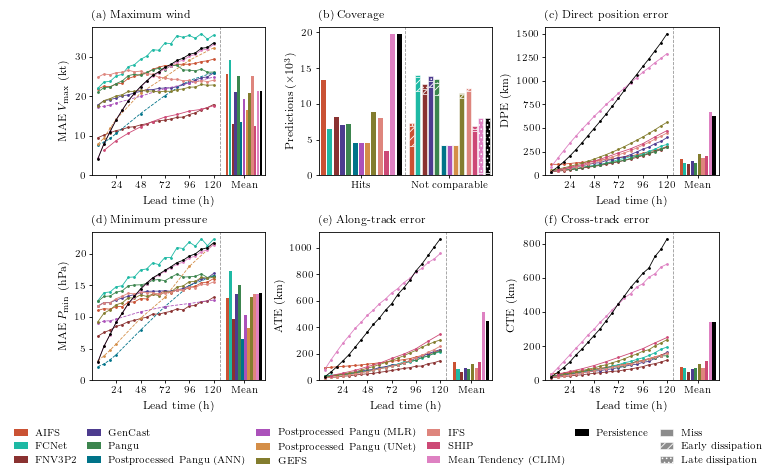

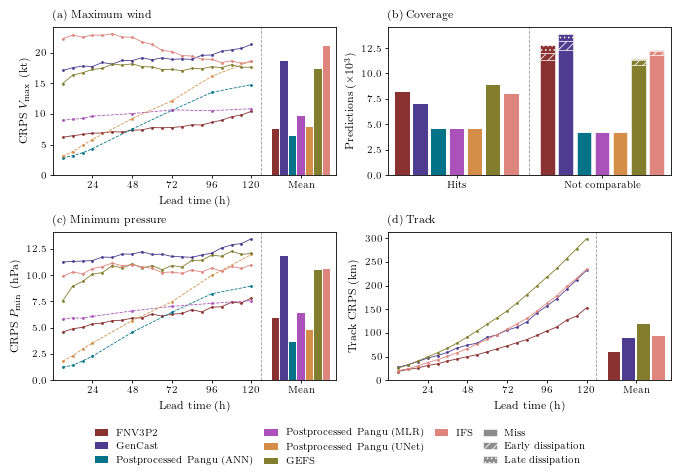

[RI] Saved RI contingency table to results/plotting_csvs/ri_contingency_2023.tex


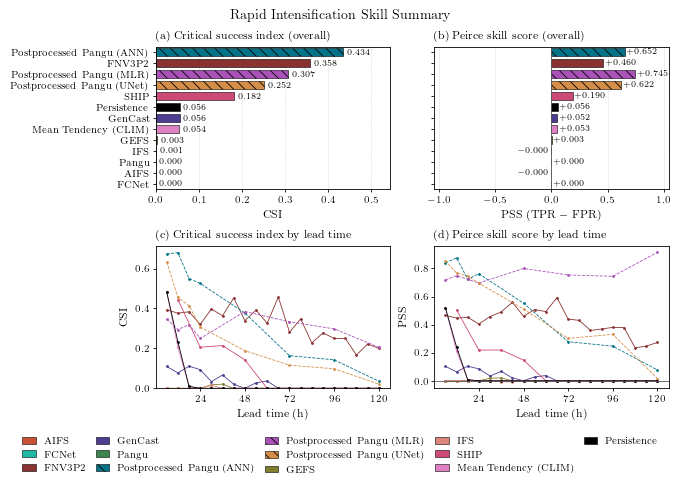

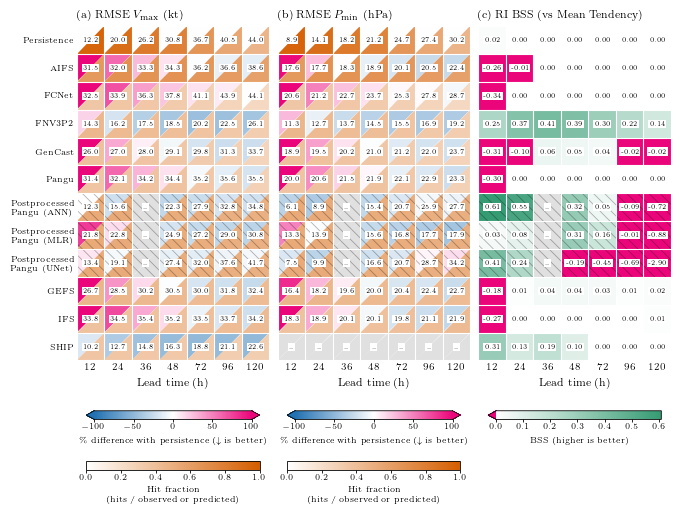

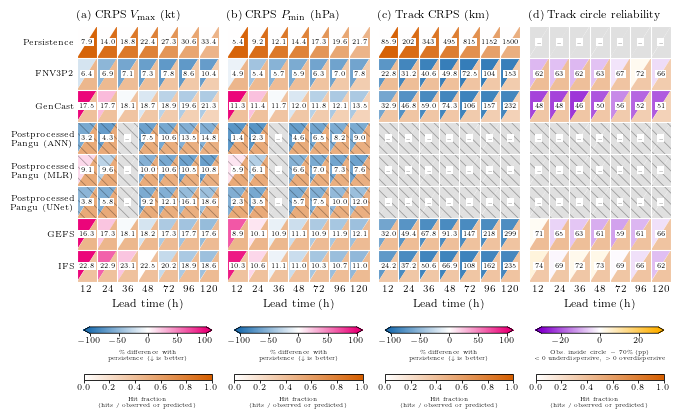

In [9]:
# Run the plotting script in the notebook so the figures are displayed inline.
# As a subprocess instead (figures are only saved):
#   subprocess.check_call([sys.executable, "plot_errors.py"], cwd=DEV_DIR)
%run plot_errors.py

In [10]:
plot_dir = Path(plot_cfg["plotting_folder"])
plot_tag = f"{plot_cfg['year']}_{plot_cfg['basin']}" if plot_cfg.get("basin") else f"{plot_cfg['year']}"

print("Coverage per model")
display(pd.read_csv(plot_dir / f"coverage_{plot_tag}.csv", index_col=0))

print("Direct position error (km) by lead time")
display(pd.read_csv(plot_dir / f"summary_DirPosErr_{plot_tag}.csv", index_col=0).round(1))

print("Probability circle: observed frequency inside the 70% circle")
pd.read_csv(plot_dir / f"summary_ProbCircle_hit70_{plot_tag}.csv", index_col=0).dropna(axis=1, how="all").round(2)

Coverage per model


,n_cases,n_comparable,frac_comparable,n_miss,frac_miss,n_early_dissipation,frac_early_dissipation,n_late_dissipation,frac_late_dissipation,n_leads,coverage_leads
model,,,,,,,,,,,
AIFS,20716,13356,0.6447,4033,0.1947,2809,0.1356,518,0.0250,20,6 12 18 24 30 36 42 48 54 60 66 72 78 84 90 96...
Mean Tendency (CLIM),27920,19838,0.7105,360,0.0129,0,0.0000,7722,0.2766,20,6 12 18 24 30 36 42 48 54 60 66 72 78 84 90 96...
FCNet,20491,6475,0.3160,11783,0.5750,1940,0.0947,293,0.0143,20,6 12 18 24 30 36 42 48 54 60 66 72 78 84 90 96...
FNV3P2,20935,8135,0.3886,11370,0.5431,693,0.0331,737,0.0352,20,6 12 18 24 30 36 42 48 54 60 66 72 78 84 90 96...
GenCast,20949,7031,0.3356,12319,0.5880,848,0.0405,751,0.0358,20,6 12 18 24 30 36 42 48 54 60 66 72 78 84 90 96...
Postprocessed Pangu (ANN),8795,4565,0.5190,4228,0.4807,2,0.0002,0,0.0000,8,6 12 18 24 48 72 96 120
Postprocessed Pangu (MLR),8795,4565,0.5190,4228,0.4807,2,0.0002,0,0.0000,8,6 12 18 24 48 72 96 120
Postprocessed Pangu (UNet),8795,4565,0.5190,4228,0.4807,2,0.0002,0,0.0000,8,6 12 18 24 48 72 96 120
Pangu,20641,7220,0.3498,11233,0.5442,1745,0.0845,443,0.0215,20,6 12 18 24 30 36 42 48 54 60 66 72 78 84 90 96...


Direct position error (km) by lead time


,AIFS,Mean Tendency (CLIM),FCNet,FNV3P2,GenCast,Pangu,Postprocessed Pangu (ANN),Postprocessed Pangu (MLR),Postprocessed Pangu (UNet),Persistence,GEFS,IFS,SHIP
6,114.5,91.2,48.5,35.9,38.2,45.2,NaN,NaN,NaN,38.9,52.7,40.7,NaN
12,115.6,177.2,51.8,43.0,54.5,51.6,NaN,NaN,NaN,85.9,63.7,49.1,54.5
18,118.3,259.0,55.0,49.2,62.5,63.6,NaN,NaN,NaN,140.6,77.9,60.4,NaN
24,124.0,338.6,62.9,58.2,80.4,64.0,NaN,NaN,NaN,201.8,93.2,73.8,83.9
30,131.1,413.1,67.2,65.7,85.4,70.1,NaN,NaN,NaN,270.0,109.9,87.0,NaN
36,135.3,486.1,79.6,75.7,101.4,82.0,NaN,NaN,NaN,342.7,127.6,101.7,113.0
42,140.6,554.1,92.3,84.6,112.3,94.3,NaN,NaN,NaN,418.8,148.0,117.7,NaN
48,151.1,622.4,103.5,94.2,128.2,96.9,NaN,NaN,NaN,494.9,170.3,135.1,150.2
54,158.7,685.4,113.2,104.1,132.0,109.8,NaN,NaN,NaN,571.3,194.7,154.3,NaN
60,167.0,749.5,129.4,116.4,156.7,125.6,NaN,NaN,NaN,649.3,218.8,173.5,190.2


Probability circle: observed frequency inside the 70% circle


,FNV3P2,GenCast,GEFS,IFS
6,0.63,0.20,0.75,0.70
12,0.62,0.48,0.71,0.74
18,0.61,0.34,0.67,0.71
24,0.63,0.48,0.65,0.69
30,0.63,0.41,0.67,0.71
36,0.62,0.46,0.63,0.72
42,0.64,0.41,0.62,0.72
48,0.63,0.50,0.61,0.73
54,0.65,0.46,0.61,0.71
60,0.67,0.50,0.59,0.70


### Add-Your-Own Model (One-Minute Setup)

1. Export your model's TC track forecasts for **2023** (00/12Z inits; 6-hourly leads up to 120 h) in the schema above: `sid`, `initial_time`, `valid_time`, plus `ensemble_idx` for ensembles, and any of `wind_max`, `pressure_min`, `lat`, `lon`. If you start from raw tracker output, use the matching step above.
2. Save the file in `eval_directory`, e.g. `<eval_directory>/my_model.csv`. Don't include `_2020` … `_2024` in the name (see the discovery rule above).
3. Re-run the **evaluation** cell, either with `select_files = null` or with your file listed in `select_files`. This writes `my_model_det_<tag>.csv` (and `_prob_` / `_ri_` when they apply).
4. Add `"my_model": "My Model"` under `pretty_names` in `plot_errors_config.yaml`, then re-run the plotting cells. Your model appears in the summary tables, scorecards and figures.